 LAB 08 — Support Vector Machines

**Name:** Syeda Dua Shah

**Student ID:** 023-24-0081

**Section:** D

**GitHub:**

**Dataset:** Telco Customer Churn (Kaggle)

**Course:** Machine Learning — BS Computer Science, 5th Semester

## Part 0 — Recap and Setup
**Objective:** reload the Telco churn data, reapply the same cleaning/encoding as Labs 2–6, and split with `stratify=y` using the same `test_size=0.2`, `random_state=42` as Labs 3, 4 and 6.

**Cleaning steps:** convert `TotalCharges` to numeric (11 blank values become NaN), fill them with 0 (these 11 customers all have `tenure = 0`, i.e. they have not been billed yet), drop `customerID`, map `Churn` to 0/1, one-hot encode the categorical columns (`drop_first=True`), then split.

In [ ]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, precision_recall_curve)

# Upload clean_churn_raw.csv to Colab first (left sidebar > Files > Upload)
df = pd.read_csv("clean_churn_raw.csv")

# Cleaning (same steps as Labs 2-6, plus the TotalCharges fix from the Lab 8 manual)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # blanks become NaN
print("Missing TotalCharges after conversion:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)   # these are customers with tenure = 0 (not billed yet)
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

y = df["Churn"]
X = df.drop(columns=["Churn"])
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# Same split settings as Labs 3, 4 and 6
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Number of encoded features:", X.shape[1])
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Churn rate (train): %.3f | Churn rate (test): %.3f" % (y_train.mean(), y_test.mean()))

Missing TotalCharges after conversion: 11
Number of encoded features: 30
X_train: (5634, 30)  X_test: (1409, 30)
Churn rate (train): 0.265 | Churn rate (test): 0.265


**Interpretation:** after the `TotalCharges` fix there are **30 encoded features** (the "25–30 dimensions" mentioned in the manual). The split gives 5,634 training and 1,409 test rows, and both keep the same churn rate (26.5%) because of `stratify=y`.

> **Important note about Labs 3, 4 and 6:** in those labs `TotalCharges` was never converted to numbers, so `get_dummies` turned it into thousands of 0/1 columns (X had 6,559 columns instead of 30). In this lab the column is converted properly, as the Lab 8 manual requires. For this reason the Decision Tree / Random Forest / Logistic Regression / KNN numbers are **re-run in Part 6** on the corrected features so that the comparison is fair (the manual allows this).

## Part 1 — Why Scaling Matters for SVM
### Task 1.1 — Unscaled vs scaled linear SVM
Two linear-kernel SVMs on the same split: one on the raw encoded features, one on `StandardScaler` features (scaler **fitted on the training set only**, then applied to the test set — no leakage). The unscaled model gets `max_iter=200000` so the cell is guaranteed to finish; without a cap it can run for a very long time.

In [ ]:
def evaluate(model, Xte, yte):
    p = model.predict(Xte)
    return dict(Accuracy=accuracy_score(yte, p), Precision=precision_score(yte, p, zero_division=0),
                Recall=recall_score(yte, p), F1=f1_score(yte, p))

# Task 1.1 step 1: linear SVM on UN-scaled features
# (max_iter is capped so the cell finishes; on raw features the solver does not converge)
t0 = time.time()
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    svm_raw = SVC(kernel="linear", random_state=42, max_iter=200000)
    svm_raw.fit(X_train, y_train)
time_raw = time.time() - t0

# Task 1.1 step 2: scaler fitted on TRAIN only, then linear SVM on scaled features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
t0 = time.time()
with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    svm_scaled = SVC(kernel="linear", random_state=42)
    svm_scaled.fit(X_train_s, y_train)
time_scaled = time.time() - t0

# Task 1.1 step 3: comparison
r_raw = evaluate(svm_raw, X_test, y_test)
r_s = evaluate(svm_scaled, X_test_s, y_test)
scaling_table = pd.DataFrame([r_raw, r_s], index=["Linear SVM - unscaled", "Linear SVM - scaled"])
scaling_table["Train time (s)"] = [time_raw, time_scaled]
scaling_table["Warnings"] = [len(w_raw), len(w_s)]
display(scaling_table.round(4))
print("Warning text (unscaled):", [str(w.message)[:90] for w in w_raw])

Warning text (unscaled): ['Solver terminated early (max_iter=200000).  Consider pre-processing your data with Standar']


,Accuracy,Precision,Recall,F1,Train time (s),Warnings
Linear SVM - unscaled,0.4017,0.1774,0.3449,0.2343,4.2009,1
Linear SVM - scaled,0.7885,0.6195,0.5267,0.5694,0.9593,0


#### Answers — Task 1.1
**(a) Differences observed.**

| Model | Accuracy | F1 | Train time | Warnings |
|---|---|---|---|---|
| Linear SVM – unscaled | 0.4017 | 0.2343 | ≈ 4.4 s | 1 ("Solver terminated early… max_iter") |
| Linear SVM – scaled | 0.7885 | 0.5694 | ≈ 1.0 s | 0 |

The unscaled model is far worse: accuracy 0.40 is even **below the 0.735 you would get by predicting "no churn" for everyone**, its F1 is 0.23 versus 0.57, it takes about 4× longer, and the solver hit the iteration cap without converging. The scaled model converged normally. (Exact times change from machine to machine, but the gap stays.)

**(b) Why this happens.** A linear SVM looks for the hyperplane with the widest margin, and the margin is measured with Euclidean distance. `TotalCharges` ranges from 0 to about 8,700, `tenure` from 0 to 72 and `MonthlyCharges` from about 18 to 119, while the dummy columns are only 0 or 1. Distances (and dot products) are therefore dominated by `TotalCharges`, and the 0/1 features that carry a lot of churn information (contract type, internet service, payment method) barely influence the geometry. To use them, the weights would have to become huge, which makes the optimisation problem badly conditioned: the solver converges extremely slowly or not at all, and the resulting boundary is poor.

**(c) Which version from now on.** The **scaled** version (`X_train_s`, `X_test_s`) for every SVM in the rest of the lab. The scaler is fitted on the training data only and then used to transform the test data. Scaled data also makes the RBF and polynomial kernels meaningful, because they are built from distances and dot products too.

## Part 2 — Kernel Comparison
### Task 2.1 — Linear vs RBF vs polynomial kernel (scaled features)
Steps 1–3: train three `SVC` models with the same `random_state`, record Accuracy, Precision, Recall, F1 and the number of support vectors in one table.

In [ ]:
results = []
models = {}
for k in ["linear", "rbf", "poly"]:
    t0 = time.time()
    m = SVC(kernel=k, random_state=42)
    m.fit(X_train_s, y_train)
    tt = time.time() - t0
    r = evaluate(m, X_test_s, y_test)
    r["Support vectors"] = m.support_.shape[0]
    r["Train time (s)"] = tt
    results.append(r); models[k] = m
kernel_table = pd.DataFrame(results, index=["linear", "rbf", "poly"])
display(kernel_table.round(4))

,Accuracy,Precision,Recall,F1,Support vectors,Train time (s)
linear,0.7885,0.6195,0.5267,0.5694,2567,0.8619
rbf,0.7928,0.6444,0.4893,0.5562,2657,0.5961
poly,0.7892,0.6421,0.4652,0.5395,2736,0.5333


**Step 4 — confusion matrix of the best kernel by F1:**

Best kernel by F1: linear
[[914 121]
 [177 197]]
Support vectors per class (n_support_): {'linear': [1286, 1281], 'rbf': [1428, 1229], 'poly': [1482, 1254]}


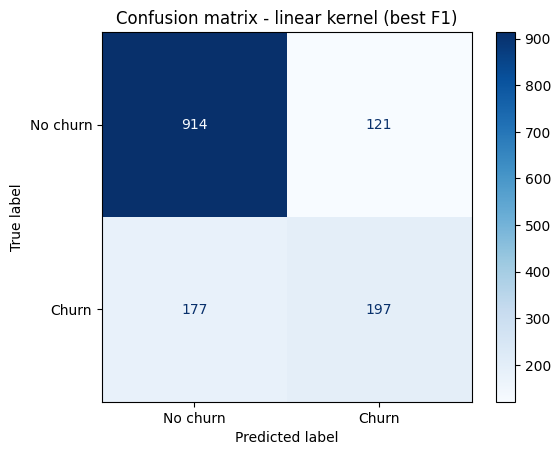

In [ ]:
best_kernel = kernel_table["F1"].idxmax()
print("Best kernel by F1:", best_kernel)
cm = confusion_matrix(y_test, models[best_kernel].predict(X_test_s))
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title(f"Confusion matrix - {best_kernel} kernel (best F1)")
plt.show()
print(cm)
print("Support vectors per class (n_support_):",
      {k: models[k].n_support_.tolist() for k in models})

**Interpretation of the plot:** the linear kernel has the best F1 (0.5694). Its confusion matrix shows 914 loyal customers and 197 churners correctly classified, 121 loyal customers wrongly flagged (false positives) and 177 churners missed (false negatives). So it still misses 177 of the 374 actual churners (recall 0.5267), which is the main weakness every default-weight model in this lab will share.

#### Answers — Task 2.1
**(a) Best F1.** The **linear kernel** (F1 = 0.5694), ahead of RBF (0.5562) and polynomial (0.5395). It is a mild surprise: theory says RBF is more flexible, so one expects it to win. But the gap is small (0.013 F1; accuracies are 0.7885 / 0.7928 / 0.7892, with RBF actually the most accurate and precise), and after one-hot encoding the churn signal is mostly additive (contract type, tenure, internet service), which a linear boundary captures well. The extra flexibility of RBF/poly mainly fits noise in the overlapping classes. This also agrees with Lab 6, where the linear Logistic Regression did well.

**(b) Most support vectors.** The **polynomial kernel** with 2,736 support vectors (48.6% of the 5,634 training rows), then RBF with 2,657 (47.2%) and linear with 2,567 (45.6%). Having almost half the training set as support vectors means the two classes overlap heavily: a very large share of points lie inside the margin or on the wrong side, so no clean, simple boundary exists. The more support vectors a kernel needs, the more complicated (and more data-dependent) the boundary it has learned.

**(c) Kernel to carry forward to Part 4.** **RBF.** Numbers: RBF is within 0.013 F1 of linear (0.5562 vs 0.5694), has the best accuracy (0.7928) and precision (0.6444) of the three, and polynomial is clearly the weakest on F1 (0.5395) and uses the most support vectors. RBF also has two tuning knobs (C and gamma), and with a small gamma it behaves almost like a linear kernel, so a grid search can recover the linear behaviour *and* go beyond it. This choice was confirmed in Part 4: tuned RBF reached F1 = 0.5785, above the best untuned kernel (linear, 0.5694).

## Part 3 — Visualizing the Margin: What Does C Actually Do?
### Task 3.1 — 2-D PCA projection and decision boundaries for three values of C
Steps 1–4: PCA(2) on the scaled **training** features (explained variance reported), three RBF SVMs on that 2-D projection with C = 0.01, 1 and 100, a mesh-grid decision-region plot for each with the training points overlaid, and the support-vector count on every plot.

Explained variance ratio: [0.3325 0.1198]
Total explained variance: 0.4522
        C  Support vectors  2-D train accuracy
0    0.01             2995              0.7346
1    1.00             2658              0.7792
2  100.00             2641              0.7813


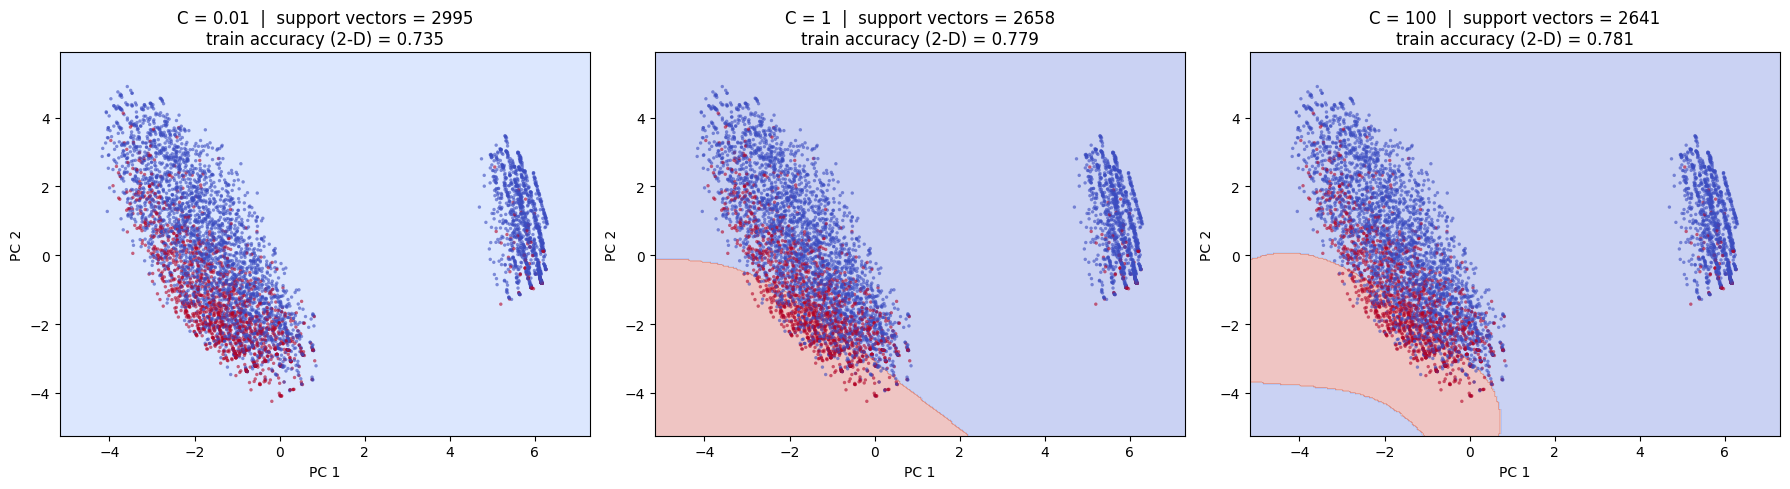

In [ ]:
pca = PCA(n_components=2, random_state=42)
Z_train = pca.fit_transform(X_train_s)          # PCA fitted on scaled TRAIN data only
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total explained variance: %.4f" % pca.explained_variance_ratio_.sum())

C_values = [0.01, 1, 100]
x_min, x_max = Z_train[:, 0].min() - 1, Z_train[:, 0].max() + 1
y_min, y_max = Z_train[:, 1].min() - 1, Z_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
c_stats = []
for ax, C in zip(axes, C_values):
    m2d = SVC(kernel="rbf", C=C, gamma="scale", random_state=42).fit(Z_train, y_train)
    Zg = m2d.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, alpha=0.3, cmap="coolwarm")
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="coolwarm", s=6, edgecolor="none", alpha=0.6)
    n_sv = m2d.support_.shape[0]
    tr_acc = accuracy_score(y_train, m2d.predict(Z_train))
    ax.set_title(f"C = {C}  |  support vectors = {n_sv}\ntrain accuracy (2-D) = {tr_acc:.3f}")
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
    c_stats.append((C, n_sv, tr_acc))
plt.tight_layout(); plt.show()
print(pd.DataFrame(c_stats, columns=["C", "Support vectors", "2-D train accuracy"]).round(4))

**Interpretation of the plots:** the two principal components explain only **45.2%** of the variance (33.25% + 11.98%), so the plot shows less than half of the information in the data. With C = 0.01 the whole plane is one colour (everything is predicted "no churn"); with C = 1 a smooth curved churn region appears in the lower-left, where the red (churn) points are concentrated; with C = 100 the boundary becomes more irregular and even creates an extra pocket in the lower-left corner.

#### Answers — Task 3.1
**(a) Smoothness vs C.** At **C = 0.01** there is no real boundary: the soft margin is so cheap to violate that the model predicts the majority class everywhere (2-D training accuracy 0.7346, exactly the share of non-churners). At **C = 1** the boundary is a single smooth curve. At **C = 100** it is more irregular and more flexible, bending around local groups of red points, because violating the margin is now very expensive. Higher C = more complex, less smooth boundary.

**(b) Support vectors vs C.** 2,995 (C = 0.01) → 2,658 (C = 1) → 2,641 (C = 100). The count falls as C grows, which matches the theory (a larger C punishes margin violations more, so the margin narrows and fewer points sit on or inside it). However, the drop is small (about 12% overall, and only 17 points between C = 1 and C = 100) because the classes overlap so strongly in this 2-D view that most points violate the margin whatever C is.

**(c) Overfitting / underfitting.** **C = 0.01 underfits**: one flat region, accuracy equal to the majority-class rate, no churners ever predicted. **C = 100 is the one closest to overfitting**: the irregular edges and the extra pocket in the lower-left corner show the boundary chasing individual points. The effect is only mild (2-D training accuracy 0.7813 vs 0.7792 for C = 1, so the extra complexity buys almost nothing). C = 1 looks like the best compromise.

**(d) Why the 2-D plot is only approximate.** (1) PCA keeps only 45.2% of the variance, so more than half of the information is invisible; points that overlap in 2-D may be separable in the real 30-D space. (2) The SVMs in the plots are trained on the 2-D projected data, so they are different models from the real 30-D SVM, not a slice of it. (3) PCA is unsupervised: it keeps the directions of largest variance, not the directions that best separate churners from loyal customers. (4) The scale of gamma and the number of support vectors depend on the dimensionality. So the plot is good for intuition about what C does, but it can mislead about how much overlap, how complex the boundary and how many support vectors the real model has.

## Part 4 — Systematic Hyperparameter Search
### Task 4.1 — GridSearchCV over C × gamma (RBF kernel, full scaled feature set)
Steps 1–2: a 4 × 5 grid (C = 0.1, 1, 10, 100; gamma = 0.0001, 0.001, 0.01, 0.1, 1) with 5-fold CV and F1 scoring on the scaled training data.

In [ ]:
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [0.0001, 0.001, 0.01, 0.1, 1]}
gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
t0 = time.time()
gs.fit(X_train_s, y_train)
time_gs = time.time() - t0
print("Grid search time (s): %.1f" % time_gs)
print("Best params:", gs.best_params_)
print("Best CV F1: %.4f" % gs.best_score_)

scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
score_df = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
score_df.index.name = "C"; score_df.columns.name = "gamma"
display(score_df.round(4))

Grid search time (s): 67.6
Best params: {'C': 100, 'gamma': 0.0001}
Best CV F1: 0.5882


gamma,0.0001,0.001,0.01,0.1,1.0
C,,,,,
0.1,0.0000,0.0000,0.5417,0.4640,0.0000
1.0,0.0000,0.5739,0.5652,0.5734,0.3261
10.0,0.5777,0.5836,0.5860,0.5270,0.3621
100.0,0.5882,0.5706,0.5876,0.5061,0.3621


**Steps 3–4 — reshape `mean_test_score` into a C × gamma grid and draw the heatmap:**

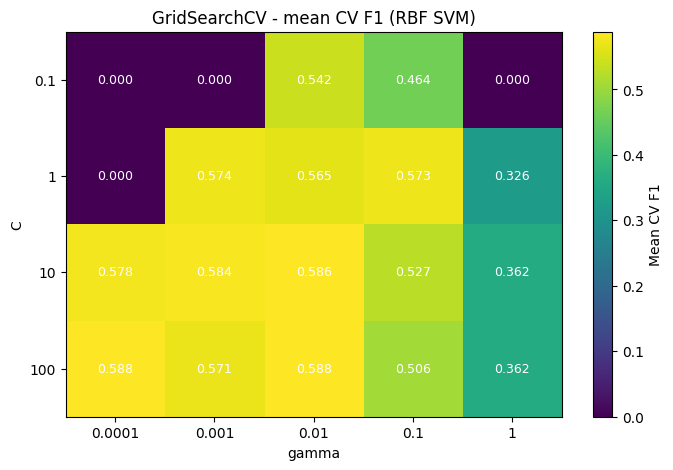

In [ ]:
plt.figure(figsize=(8, 5))
plt.imshow(scores, cmap="viridis", aspect="auto")
plt.colorbar(label="Mean CV F1")
plt.xticks(range(len(param_grid["gamma"])), param_grid["gamma"])
plt.yticks(range(len(param_grid["C"])), param_grid["C"])
plt.xlabel("gamma"); plt.ylabel("C"); plt.title("GridSearchCV - mean CV F1 (RBF SVM)")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        plt.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
plt.show()

**Interpretation of the heatmap:** there is a broad yellow ridge of good scores (about 0.57–0.59) running diagonally across the grid (small gamma needs large C, large gamma needs smaller C). Two regions are bad: the top-left corner (small C with small gamma) scores 0.000 because the model never predicts churn, and the whole gamma = 1 column is poor (0.33–0.36) because the boundary becomes too wiggly and overfits.

**Step 5 — refit the best estimator and evaluate it on the held-out test set:**

{'Accuracy': 0.7942, 'Precision': 0.6338, 'Recall': 0.5321, 'F1': 0.5785}
[[920 115]
 [175 199]]
Untuned RBF F1 (Part 2): 0.5562 | Tuned RBF F1: 0.5785 | CV-vs-test gap: 0.0098


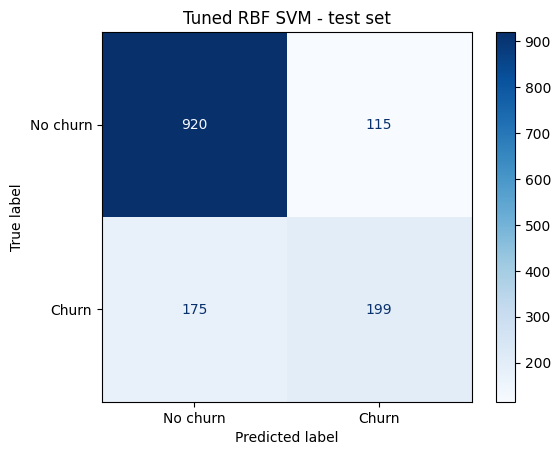

In [ ]:
best_svm = gs.best_estimator_
tuned_res = evaluate(best_svm, X_test_s, y_test)
print({k: round(v, 4) for k, v in tuned_res.items()})
cm = confusion_matrix(y_test, best_svm.predict(X_test_s))
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(cmap="Blues")
plt.title("Tuned RBF SVM - test set"); plt.show()
print(cm)
print("Untuned RBF F1 (Part 2): %.4f | Tuned RBF F1: %.4f | CV-vs-test gap: %.4f" %
      (kernel_table.loc["rbf", "F1"], tuned_res["F1"], gs.best_score_ - tuned_res["F1"]))

**Interpretation:** on the test set the tuned RBF SVM reaches accuracy 0.7942, precision 0.6338, recall 0.5321 and F1 0.5785. It correctly finds 199 of the 374 churners and still misses 175.

#### Answers — Task 4.1
**(a) Best values.** **C = 100 and gamma = 0.0001**, with a cross-validated F1 of **0.5882**.

**(b) Best region or not?** There is a *region*, not a single sharp optimum. The top scores are almost tied: 0.5882 (C = 100, γ = 0.0001), 0.5876 (C = 100, γ = 0.01), 0.5860 (C = 10, γ = 0.01) and 0.5836 (C = 10, γ = 0.001) — differences of less than 0.005, which is within cross-validation noise. So inside the ridge the model is **not sensitive** to the exact values, but it is very sensitive at the extremes (F1 drops to 0.000 for tiny C/gamma and to about 0.33–0.36 for gamma = 1). One more observation: the winner sits at the edge of the grid (the smallest gamma), so a wider grid with even smaller gamma would be worth trying.

**(c) CV score vs test score.** They agree closely: 0.5882 (CV) vs 0.5785 (test), a gap of only 0.0098. That suggests the model generalises and the search did not overfit. A large gap (for example 0.05 or more) would suggest overfitting to the training folds or to the hyperparameter search, data leakage, or a test set that is not representative of the training data.

**(d) Tuned vs untuned RBF.** Untuned RBF (Part 2): F1 0.5562, recall 0.4893, precision 0.6444. Tuned RBF: F1 **0.5785** (+0.0223), recall 0.5321 (+0.0428), precision 0.6338, accuracy 0.7942 (vs 0.7928). The gain is modest, but the cost is small too (about 70 s for the 100 fits of the search on this machine vs under 1 s for a single fit), so the tuning was worth it. It also lifts the RBF model above the best untuned kernel (linear, F1 0.5694).

## Part 5 — Class Imbalance and the Business Trade-off
### Task 5.1 — RBF SVM with and without `class_weight='balanced'`
Steps 1–2: use the best (C, gamma) from Part 4 (C = 100, gamma = 0.0001) and train two RBF SVMs, then compare Precision, Recall, F1 and the confusion matrices on the test set. The balanced model is trained with `probability=True` so it can give probability-like scores for step 3.

In [ ]:
bestC, bestG = gs.best_params_["C"], gs.best_params_["gamma"]
svm_default = SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight=None, random_state=42).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight="balanced",
              probability=True, random_state=42).fit(X_train_s, y_train)   # probability=True enables predict_proba

rows, cms = [], {}
for name, m in [("class_weight=None", svm_default), ("class_weight='balanced'", svm_bal)]:
    rows.append(evaluate(m, X_test_s, y_test))
    cms[name] = confusion_matrix(y_test, m.predict(X_test_s))
cw_table = pd.DataFrame(rows, index=["class_weight=None", "class_weight='balanced'"])
display(cw_table.round(4))
for name, c in cms.items():
    print(name, "\n", c)

class_weight=None 
 [[920 115]
 [175 199]]
class_weight='balanced' 
 [[671 364]
 [ 67 307]]


,Accuracy,Precision,Recall,F1
class_weight=None,0.7942,0.6338,0.5321,0.5785
class_weight='balanced',0.6941,0.4575,0.8209,0.5876


**Interpretation of the table and the confusion matrices:** switching to `class_weight='balanced'` makes the model catch many more churners (false negatives drop from 175 to 67) at the price of many more false alarms (false positives rise from 115 to 364).

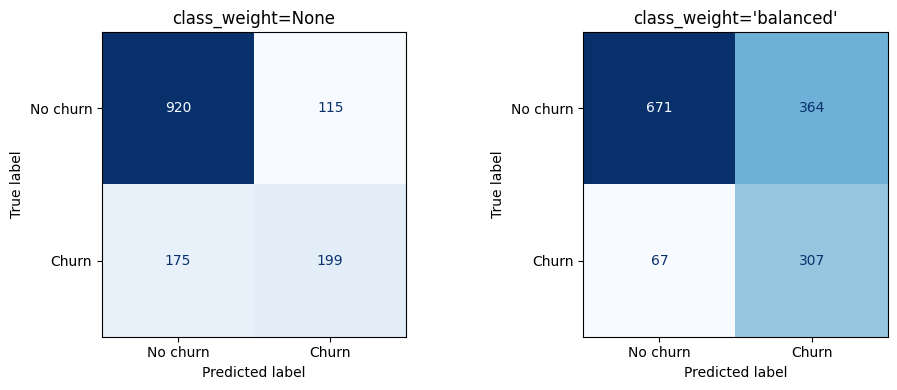

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, c) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(c, display_labels=["No churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

**Interpretation:** the confusion matrices above show the shift: the default model is "cautious" (few false alarms, many missed churners), the balanced model is "aggressive" (many false alarms, few missed churners). Accuracy drops (0.7942 → 0.6941), but accuracy is misleading for a 26.5% minority class.

**Step 3 — ROC curve of the balanced model with the default operating point:**

AUC: 0.8327 | default predict() point: FPR=0.352 TPR=0.821
Customers flagged if we cut the Platt probabilities at 0.5: 0 of 1409


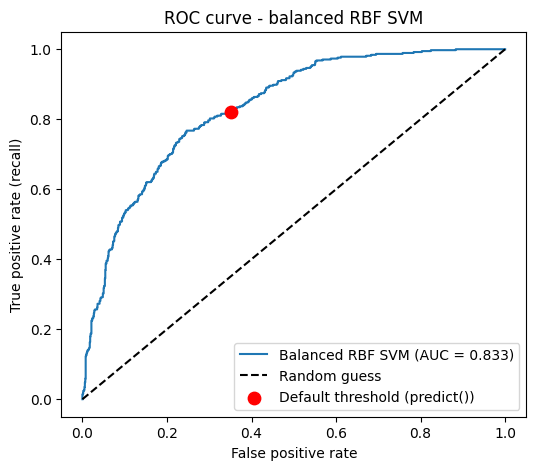

In [ ]:
proba = svm_bal.predict_proba(X_test_s)[:, 1]          # probability-like scores (Platt scaling)
fpr, tpr, thr = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
pred_bal = svm_bal.predict(X_test_s)
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)          # operating point of the default predict()
pred_05 = (proba >= 0.5).astype(int)
tn5, fp5, fn5, tp5 = confusion_matrix(y_test, pred_05).ravel()

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Balanced RBF SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.scatter([op_fpr], [op_tpr], color="red", s=80, zorder=5, label="Default threshold (predict())")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curve - balanced RBF SVM"); plt.legend(); plt.show()
print("AUC: %.4f | default predict() point: FPR=%.3f TPR=%.3f" % (auc, op_fpr, op_tpr))
print("Customers flagged if we cut the Platt probabilities at 0.5:", int(pred_05.sum()), "of", len(pred_05))

**Interpretation of the ROC curve:** the curve is clearly above the diagonal (AUC = **0.8327**), so the scores rank churners above loyal customers well. The red point is where the default threshold puts the model: it catches about 82% of churners (TPR 0.821) while wrongly flagging about 35% of loyal customers (FPR 0.352). Moving the threshold would slide this point along the curve to trade recall for false alarms.

#### Answers — Task 5.1
**(a) How precision and recall moved.** Precision fell from **0.6338 to 0.4575** (−0.1763) and recall rose from **0.5321 to 0.8209** (+0.2888). F1 went from 0.5785 to 0.5876 (+0.0091) and accuracy fell from 0.7942 to 0.6941. In counts: 108 more churners were caught (false negatives 175 → 67) but 249 more loyal customers were flagged (false positives 115 → 364), about 2.3 extra false alarms for every extra churner caught.

**(b) Which error is more costly, and which model to deploy.** For a telecom company, **missing a real churner (false negative) is normally more costly**: the company loses all future monthly revenue from that customer and has to spend money to acquire a replacement, while a false positive only costs one unnecessary retention action (a call, a small discount or offer). The balanced model is better as long as saving one churner is worth more than about 2.3 retention offers (249 extra false alarms ÷ 108 extra churners caught), which is realistic when offers are cheap compared with a customer's lifetime revenue (this is an assumption — the lab gives no cost figures). So I would **recommend deploying the `class_weight='balanced'` model**. If the retention budget were very limited, the default model's higher precision (0.63 vs 0.46) would be the better choice.

**(c) Probability-like scores.** SVM does not output probabilities naturally, so I enabled **`probability=True`** in `SVC()` and used `predict_proba()`. This makes scikit-learn fit a Platt-scaling (sigmoid) calibration on top of the SVM scores using an internal 5-fold cross-validation, which makes training noticeably slower. A caution from my run: the calibrated probabilities reflect the 26.5% base churn rate, and if you cut them at 0.5 **no customer (0 of 1,409) is flagged**, so the default `predict()` (the sign of the decision function) is the meaningful default threshold and is what the red point shows. The alternative without `probability=True` is `decision_function()`, which gives scores that work for ROC too.

## Part 6 — Model Showdown: SVM vs. Everything Else
### Task 6.1 — One scoreboard for five algorithms and one final model
Steps 1–3: I re-ran Decision Tree, tuned Random Forest (same grid as Lab 4), Logistic Regression (`max_iter=2000`) and KNN (K chosen by 5-fold CV on the training data) on **exactly this lab's split and corrected features**, as the manual allows, so the comparison is fair. The SVM row is the better of the two tuned SVMs (by F1).

In [ ]:
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),
                       {"n_estimators": [20, 50], "max_depth": [10, 20], "min_samples_split": [2, 5]},
                       cv=5, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)
rf = rf_grid.best_estimator_
lr = LogisticRegression(max_iter=2000, random_state=42).fit(X_train_s, y_train)
# choose K by 5-fold CV on the training set (not on the test set)
k_list = [1, 3, 5, 7, 9, 11, 15, 21]
cv_f1 = {k: cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5, scoring="f1").mean() for k in k_list}
best_k = max(cv_f1, key=cv_f1.get)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
print("RF best params:", rf_grid.best_params_, "| KNN best K (CV):", best_k)

# Pick the better SVM (by test F1) from Parts 4/5 as "best SVM"
cands = {"SVM (tuned RBF)": (best_svm, tuned_res), "SVM (tuned RBF, balanced)": (svm_bal, evaluate(svm_bal, X_test_s, y_test))}
svm_name = max(cands, key=lambda n: cands[n][1]["F1"])
final_svm = cands[svm_name][0]

def fit_time(est, Xtr):
    t0 = time.time(); est.fit(Xtr, y_train); return time.time() - t0
t_dt = fit_time(DecisionTreeClassifier(random_state=42), X_train)
t_rf = fit_time(RandomForestClassifier(random_state=42, **rf_grid.best_params_), X_train)
t_lr = fit_time(LogisticRegression(max_iter=2000, random_state=42), X_train_s)
t_knn = fit_time(KNeighborsClassifier(n_neighbors=best_k), X_train_s)
t_svm = fit_time(SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight="balanced", probability=True, random_state=42), X_train_s)

comp = pd.DataFrame([
    dict(Model="Decision Tree", **evaluate(dt, X_test, y_test), **{"Train time (s)": t_dt}),
    dict(Model="Random Forest (tuned)", **evaluate(rf, X_test, y_test), **{"Train time (s)": t_rf}),
    dict(Model="Logistic Regression", **evaluate(lr, X_test_s, y_test), **{"Train time (s)": t_lr}),
    dict(Model=f"KNN (K={best_k})", **evaluate(knn, X_test_s, y_test), **{"Train time (s)": t_knn}),
    dict(Model=svm_name, **cands[svm_name][1], **{"Train time (s)": t_svm}),
]).set_index("Model")
display(comp.round(4))
print("Best SVM chosen:", svm_name)

# Saved numbers from the earlier labs (their features included the un-converted TotalCharges text column)
saved = pd.DataFrame({"Accuracy": [0.7984, 0.7942, 0.7764, 0.7402], "Precision": [0.6630, 0.6591, 0.5931, 0.5741],
                      "Recall": [0.4893, 0.4652, 0.5027, 0.0829], "F1": [0.5631, 0.5455, 0.5441, 0.1449]},
                     index=["Decision Tree (Lab 3)", "Random Forest (Lab 4)", "Logistic Regression (Lab 6)", "KNN (Lab 6)"])
display(saved)

RF best params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50} | KNN best K (CV): 21
Best SVM chosen: SVM (tuned RBF, balanced)


,Accuracy,Precision,Recall,F1,Train time (s)
Model,,,,,
Decision Tree,0.7260,0.4838,0.4786,0.4812,0.0234
Random Forest (tuned),0.7913,0.6351,0.5027,0.5612,0.1811
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.0146
KNN (K=21),0.7708,0.5702,0.5535,0.5617,0.0012
"SVM (tuned RBF, balanced)",0.6941,0.4575,0.8209,0.5876,4.6417


,Accuracy,Precision,Recall,F1
Decision Tree (Lab 3),0.7984,0.6630,0.4893,0.5631
Random Forest (Lab 4),0.7942,0.6591,0.4652,0.5455
Logistic Regression (Lab 6),0.7764,0.5931,0.5027,0.5441
KNN (Lab 6),0.7402,0.5741,0.0829,0.1449


**Note on the two tables:** the second table is the numbers saved from Labs 3, 4 and 6. They are *not* comparable with this lab because those labs used the 6,559-column feature set created by the unconverted `TotalCharges` column. For example KNN had F1 = 0.1449 there but 0.5617 here, and the Decision Tree had F1 = 0.5631 there but 0.4812 here. The first table is the fair one.

**Step 3 — one bar chart of F1 for the five models:**

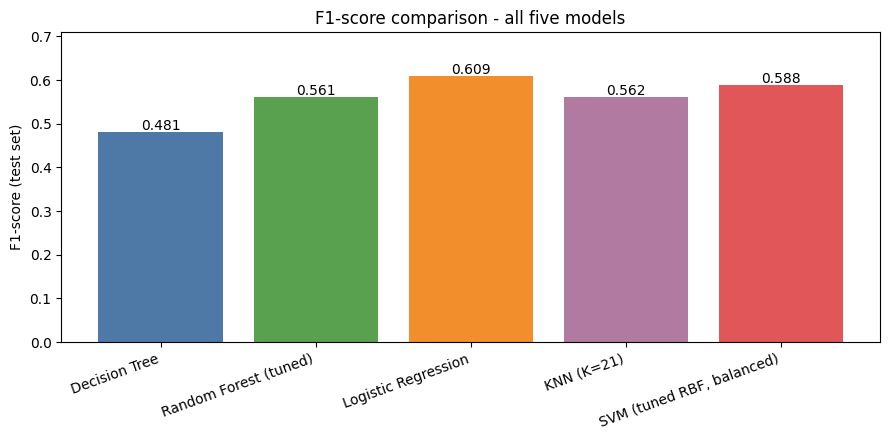

In [ ]:
plt.figure(figsize=(9, 4.5))
bars = plt.bar(comp.index, comp["F1"], color=["#4E79A7", "#59A14F", "#F28E2B", "#B07AA1", "#E15759"])
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f"{b.get_height():.3f}", ha="center")
plt.ylabel("F1-score (test set)"); plt.title("F1-score comparison - all five models")
plt.xticks(rotation=20, ha="right"); plt.ylim(0, comp["F1"].max() + 0.1); plt.tight_layout(); plt.show()

**Interpretation of the bar chart:** Logistic Regression has the highest F1 (0.609), followed by the balanced SVM (0.588), KNN and Random Forest (both about 0.56), and the Decision Tree (0.481). F1 alone hides that the balanced SVM is very different from the others: it trades precision for a much higher recall.

#### Answers — Task 6.1
**(a) Winners.** **Logistic Regression wins on F1** (0.6092, also the best accuracy 0.8070 and precision 0.6584 among the models with similar behaviour). **The balanced SVM wins on recall** (0.8209 vs 0.5668 for Logistic Regression and 0.5535 for KNN). They are **not the same model**.

**(b) Was the SVM's extra cost worth it?** SVM is the slowest: one fit of the tuned, probability-enabled model took about 4.7 s (about 0.6 s without `probability=True`), plus about 72 s for the grid search, compared with about 0.02 s for the Decision Tree, 0.18 s for the Random Forest and 0.015 s for Logistic Regression. Judged by F1 it was **not** worth it: Logistic Regression is better (0.6092 vs 0.5876) and about 300× faster. The only thing the SVM gives is the much higher recall (0.8209), but that comes mostly from `class_weight='balanced'`, not from the SVM algorithm itself (I did not test Logistic Regression with balanced weights in this lab, so I cannot say how close it would get).

**(c) Recommended model.** I recommend deploying the **balanced RBF SVM**, because it catches 82.1% of churners (recall 0.8209, 307 of 374) against 56.7% for Logistic Regression, and its F1 (0.5876) is only 0.0216 below the best model's, with AUC 0.8327. The price is lower precision (0.4575 vs 0.6584) and lower accuracy (0.6941 vs 0.8070), which is acceptable under the Part 5 argument that a missed churner costs more than an unnecessary retention offer. If the retention campaign had a tight budget or the company cared more about overall accuracy and precision, Logistic Regression (simple, fast, F1 0.6092) would be the better choice.

## Part 7 — Final Predictions and Wrap-Up
### Task 7.1 — Predictions file and executive summary
Step 1: save `svm_predictions.csv` with the true label, the predicted label and the predicted churn probability for the final chosen model (the balanced RBF SVM).

In [ ]:
final_name = svm_name   # chosen in Part 6(c): best recall for the churn use-case (see written justification)
print("Final chosen model:", final_name)
final_models = {"Decision Tree": (dt, X_test), "Random Forest (tuned)": (rf, X_test), "Logistic Regression": (lr, X_test_s),
                f"KNN (K={best_k})": (knn, X_test_s), svm_name: (final_svm, X_test_s)}
fm, Xf = final_models[final_name]
score = fm.predict_proba(Xf)[:, 1] if hasattr(fm, "predict_proba") else fm.decision_function(Xf)
out = pd.DataFrame({"true_label": y_test.values, "predicted_label": fm.predict(Xf), "churn_probability": score},
                   index=y_test.index)
out.to_csv("svm_predictions.csv", index=False)
print(out.head()); print("Saved svm_predictions.csv with", len(out), "rows")

Final chosen model: SVM (tuned RBF, balanced)
      true_label  predicted_label  churn_probability
437            0                0           0.102568
2280           0                1           0.478445
2235           0                0           0.102101
4460           0                1           0.474660
3761           0                0           0.101731
Saved svm_predictions.csv with 1409 rows


**Interpretation:** the file has one row per test customer (1,409 rows). `churn_probability` is the Platt-scaled score, which is why even customers predicted as churners can have probabilities below 0.5: `predicted_label` comes from the SVM decision function, not from a 0.5 cut on this column.

**Step 2 — Executive Summary**

I chose the RBF-kernel SVM with `class_weight='balanced'` (C = 100, gamma = 0.0001) as the final model for predicting customer churn on the Telco dataset. On the 1,409 held-out customers it reaches recall 0.8209, precision 0.4575, F1 0.5876, accuracy 0.6941 and ROC AUC 0.8327. The main trade-off was made in Part 5: balancing the classes raised recall by 0.29 (175 → 67 missed churners) but cost 0.18 in precision (115 → 364 false alarms), which I accept because missing a churner is normally more expensive than a wasted retention offer. Scaling was essential (an unscaled linear SVM scored only 0.40 accuracy), and tuning C and gamma added about 0.02 F1 over the default RBF SVM. Logistic Regression had a slightly better F1 (0.6092) and trains far faster, so it is the better choice if precision or budget matters more than recall. One limitation is that the cost trade-off is based on an assumption, because no real cost of a retention offer or of a lost customer was available; another is that all results come from a single train/test split.

## Final Reflection
**(a) Most surprising result.** Two things: the simple **linear kernel beat RBF and polynomial** on F1 (0.5694 vs 0.5562 and 0.5395) before any tuning, and the unscaled linear SVM was not just worse but **worse than predicting "no churn" for everyone** (accuracy 0.40 vs 0.735). I was also surprised that fixing `TotalCharges` changed other models a lot (KNN F1 from 0.14 to 0.56).

**(b) With one more hour.** I would (1) tune the decision threshold (or the class weight) to hit a target recall/precision instead of using the all-or-nothing `balanced` setting, (2) test Logistic Regression with `class_weight='balanced'` to see whether the SVM's recall advantage is really about the algorithm, (3) widen the grid to smaller gamma values because the best value was on the edge, and (4) try SMOTE and feature engineering (for example tenure buckets or services-per-customer).